# 04 — Análisis exploratorio univariado y bivariado

**Etapa CRISP-DM:** EDA · **Semana 8** · **OE4**

## Objetivo
Describir las variables del dataset analítico (univariado) y explorar su relación
con la participación en internacionalización (bivariado). El énfasis está en el
**subconjunto de pregrado**, foco del proyecto.

## Contexto
Con el dataset analítico ya construido (notebook 03), aquí se producen las
primeras distribuciones y cruces que orientarán el análisis profundo (semana 9)
y la selección de variables para el modelamiento.

In [1]:
import sys, os
from pathlib import Path
# Permitir importar el paquete src desde notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 12

from src import config, utils, internationalization as intl
print('Entorno listo. Raiz del proyecto:', ROOT)

Entorno listo. Raiz del proyecto: C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO


In [2]:
df = pd.read_parquet(config.ANALYTIC_DATASET)
preg = df[df['ES_PREGRADO']].copy()
print('Universo total:', len(df), '| Pregrado:', len(preg))
print('Participantes pregrado:', int(preg['PARTICIPA'].sum()),
      f"({100*preg['PARTICIPA'].mean():.2f}%)")

Universo total: 233987 | Pregrado: 140422
Participantes pregrado: 5821 (4.15%)


## 1. Univariado — variables categóricas
Distribución de nivel, facultad, género y tipo de admisión.

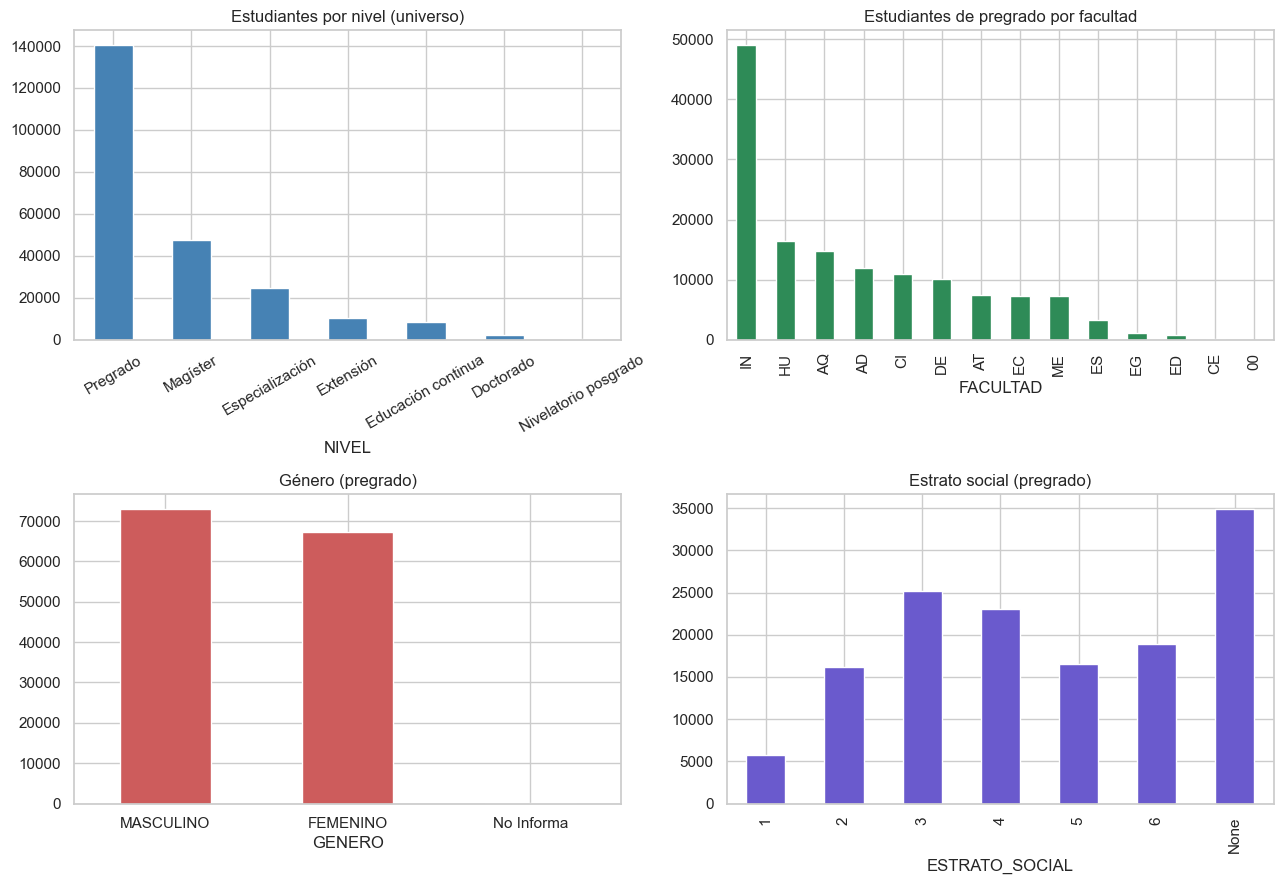

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
df['NIVEL'].value_counts().head(7).plot.bar(ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Estudiantes por nivel (universo)')
axes[0, 0].tick_params(axis='x', rotation=30)

preg['FACULTAD'].value_counts().plot.bar(ax=axes[0, 1], color='seagreen')
axes[0, 1].set_title('Estudiantes de pregrado por facultad')

preg['GENERO'].value_counts().plot.bar(ax=axes[1, 0], color='indianred')
axes[1, 0].set_title('Género (pregrado)')
axes[1, 0].tick_params(axis='x', rotation=0)

preg['ESTRATO_SOCIAL'].value_counts(dropna=False).sort_index().plot.bar(ax=axes[1, 1], color='slateblue')
axes[1, 1].set_title('Estrato social (pregrado)')
plt.tight_layout()
utils.save_fig(fig, 'fig_univariado_categoricas.png')
plt.show()

### Resultado e interpretación
El pregrado es el nivel más numeroso del universo. La población de pregrado se
concentra en unas pocas facultades grandes (Ingeniería es la de mayor volumen),
con una distribución de género relativamente equilibrada y una fuerte presencia
de estratos 3-6. Una fracción notable de estudiantes tiene `ESTRATO_SOCIAL`
ausente, lo que refuerza la decisión de tratarlo como categórica con nivel "Sin
dato" y de usarlo solo para lectura de equidad.

## 2. Univariado — variables numéricas de desempeño
Distribución de PGA, percentil, avance y puntaje ICFES.

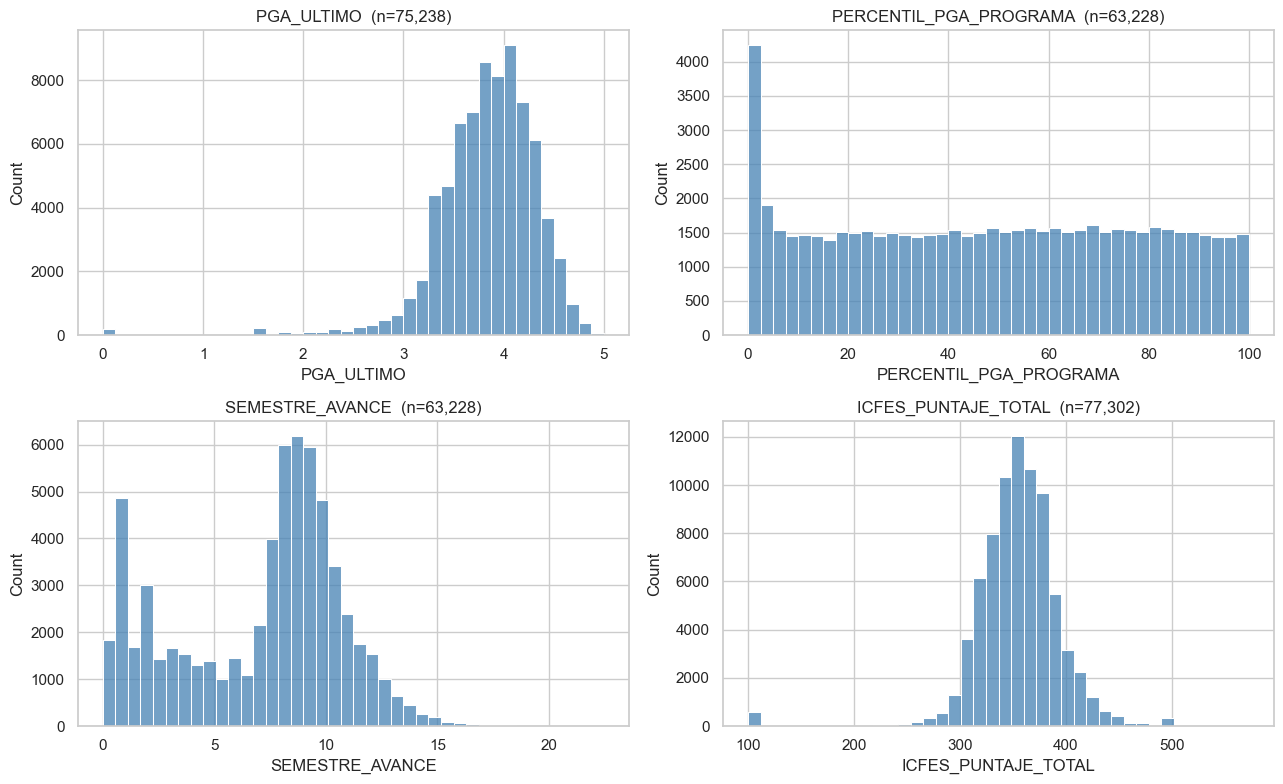

,PGA_ULTIMO,PERCENTIL_PGA_PROGRAMA,SEMESTRE_AVANCE,ICFES_PUNTAJE_TOTAL
count,75238.00,63228.00,63228.00,77302.00
mean,3.83,47.81,7.11,354.82
std,0.50,29.96,3.69,40.40
min,0.00,0.05,0.00,100.00
25%,3.58,21.43,3.87,334.00
50%,3.88,48.14,8.18,356.00
75%,4.16,73.79,9.66,376.00
max,5.00,100.00,22.46,573.00


In [4]:
num = ['PGA_ULTIMO', 'PERCENTIL_PGA_PROGRAMA', 'SEMESTRE_AVANCE', 'ICFES_PUNTAJE_TOTAL']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), num):
    data = preg[col].dropna()
    sns.histplot(data, bins=40, ax=ax, color='steelblue')
    ax.set_title(f'{col}  (n={len(data):,})')
plt.tight_layout()
utils.save_fig(fig, 'fig_univariado_numericas.png')
plt.show()
preg[num].describe().round(2)

### Resultado e interpretación
El PGA de pregrado se concentra alrededor de 3.8-4.0 con cola inferior (primeros
semestres y casos de bajo rendimiento). El percentil de PGA por programa es, por
construcción, aproximadamente uniforme (mediana ~48). El avance en semestres
muestra una masa importante en etapas intermedias/avanzadas. El puntaje ICFES se
distribuye de forma aproximadamente simétrica alrededor de ~355. Estas escalas
son coherentes y no requieren transformaciones adicionales para el análisis
descriptivo.

## 3. Bivariado — tasa de participación por categoría
Comparamos la tasa de participación entre grupos.

In [5]:
def tasa_por_categoria(data, col, min_n=200):
    t = data.groupby(col)['PARTICIPA'].agg(['mean', 'count'])
    t = t[t['count'] >= min_n]
    t['tasa_%'] = (100 * t['mean']).round(2)
    return t[['count', 'tasa_%']].sort_values('tasa_%', ascending=False)

print('=== Tasa por facultad (pregrado) ==='); display(tasa_por_categoria(preg, 'FACULTAD'))
print('=== Tasa por género (pregrado) ==='); display(tasa_por_categoria(preg, 'GENERO'))
print('=== Tasa por estrato (pregrado) ==='); display(tasa_por_categoria(preg, 'ESTRATO_SOCIAL'))

=== Tasa por facultad (pregrado) ===


,count,tasa_%
FACULTAD,,
AD,12008,12.25
AQ,14844,5.71
EC,7234,5.67
DE,10034,4.51
EG,1110,3.69
HU,16353,3.58
AT,7489,3.43
IN,48991,3.12
CI,10930,1.98


=== Tasa por género (pregrado) ===


,count,tasa_%
GENERO,,
FEMENINO,67347,4.65
MASCULINO,73019,3.68


=== Tasa por estrato (pregrado) ===


,count,tasa_%
ESTRATO_SOCIAL,,
6,18847,9.48
5,16541,6.26
4,23034,3.33
3,25136,0.94
2,16234,0.43
1,5714,0.42


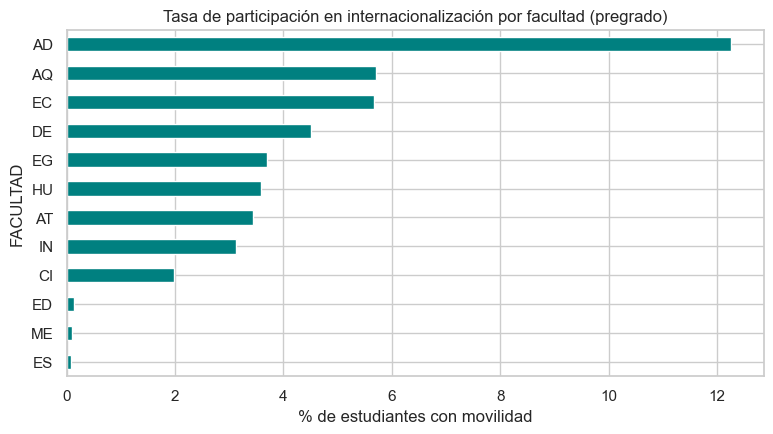

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
tf = tasa_por_categoria(preg, 'FACULTAD')
tf['tasa_%'].sort_values().plot.barh(ax=ax, color='teal')
ax.set_title('Tasa de participación en internacionalización por facultad (pregrado)')
ax.set_xlabel('% de estudiantes con movilidad')
utils.save_fig(fig, 'fig_tasa_por_facultad.png')
plt.show()

### Resultado e interpretación
Aparecen diferencias marcadas entre grupos:

- **Facultad:** la tasa de participación va desde ~0.1% hasta **~12%** según la
  facultad (Administración muestra la tasa más alta; Arquitectura, Economía y
  Derecho también destacan). Es la dimensión con mayor poder discriminante
  observado.
- **Género:** la tasa es algo mayor en mujeres (~4.7%) que en hombres (~3.7%).
- **Estrato:** existe un **gradiente socioeconómico** claro: la tasa crece de
  forma monótona con el estrato (de ~0.4% en estratos 1-2 a **~9.5%** en estrato
  6). Es un hallazgo relevante de equidad que debe interpretarse como asociación,
  no causa, y comunicarse con cuidado.

**Decisión:** facultad/programa y variables socioeconómicas son candidatas
importantes para el EDA profundo (semana 9) y potenciales predictores; la lectura
de estrato se enmarcará explícitamente como análisis de equidad.

## 4. Bivariado — desempeño académico y participación
Comparamos distribuciones de variables numéricas entre participantes y no participantes.

C:\Users\JUAN DAVID\AppData\Local\Temp\ipykernel_2932\217434971.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No participa', 'Participa'])
C:\Users\JUAN DAVID\AppData\Local\Temp\ipykernel_2932\217434971.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No participa', 'Participa'])


C:\Users\JUAN DAVID\AppData\Local\Temp\ipykernel_2932\217434971.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No participa', 'Participa'])
C:\Users\JUAN DAVID\AppData\Local\Temp\ipykernel_2932\217434971.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No participa', 'Participa'])


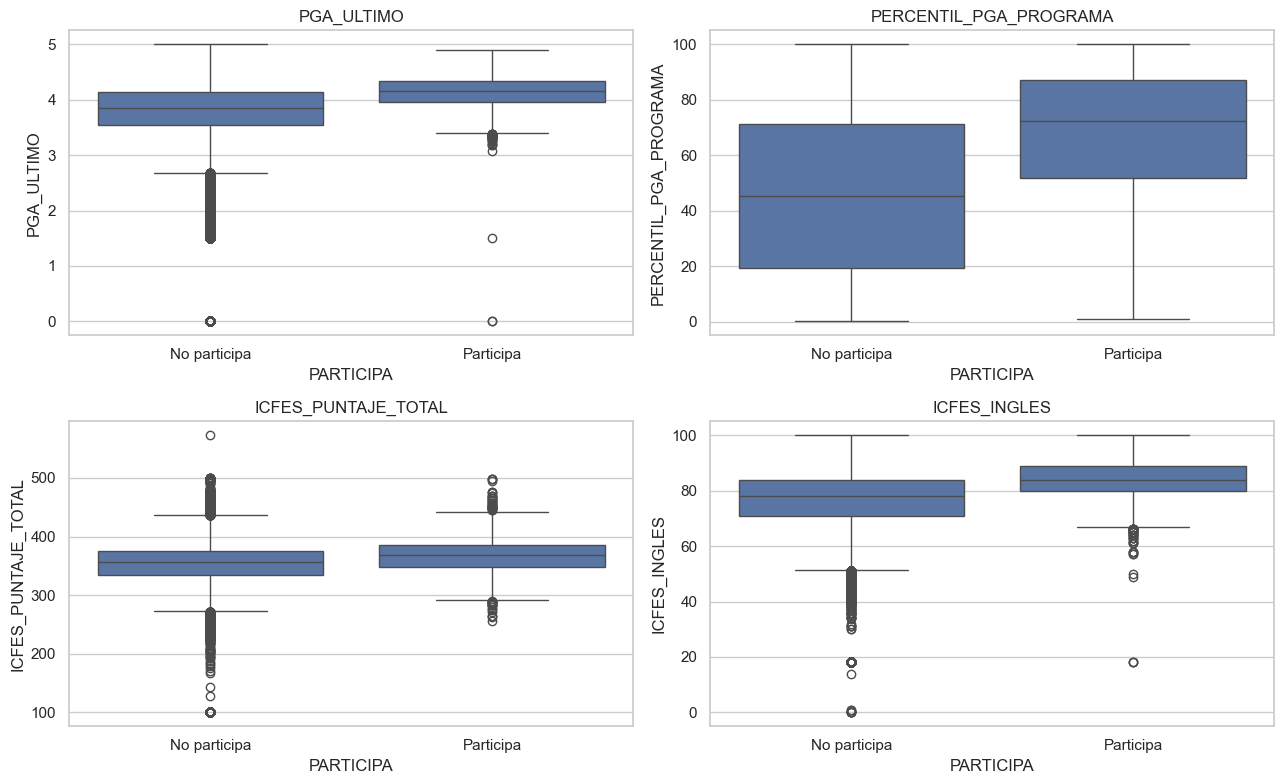

PARTICIPA,0,1,diferencia
PGA_ULTIMO,3.81,4.14,0.33
PERCENTIL_PGA_PROGRAMA,45.79,67.73,21.94
ICFES_PUNTAJE_TOTAL,354.33,368.44,14.11
ICFES_INGLES,77.44,84.62,7.18
SEMESTRE_AVANCE,6.93,8.87,1.95
NIVEL_INGLES,5.05,6.25,1.20


In [7]:
comparar = ['PGA_ULTIMO', 'PERCENTIL_PGA_PROGRAMA', 'ICFES_PUNTAJE_TOTAL', 'ICFES_INGLES']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), comparar):
    sns.boxplot(data=preg, x='PARTICIPA', y=col, ax=ax)
    ax.set_title(col)
    ax.set_xticklabels(['No participa', 'Participa'])
plt.tight_layout()
utils.save_fig(fig, 'fig_bivariado_desempeno.png')
plt.show()

resumen = preg.groupby('PARTICIPA')[comparar + ['SEMESTRE_AVANCE', 'NIVEL_INGLES']].mean().T
resumen['diferencia'] = resumen[1] - resumen[0]
resumen.round(2)

### Resultado e interpretación
Los participantes muestran, en promedio, **mejor desempeño y mejor perfil de
ingreso** que los no participantes:

- PGA final más alto (~4.14 vs ~3.81).
- Percentil de PGA por programa mucho mayor (~68 vs ~46): los participantes
  tienden a estar en la mitad superior de su programa.
- Puntaje ICFES total y de inglés más altos.
- Mayor avance (más semestres cursados), consistente con que la movilidad suele
  ocurrir en etapas intermedias/avanzadas de la carrera.

Estas diferencias son coherentes con la intuición institucional (la movilidad
suele exigir buen desempeño y cierto avance) y sugieren que las variables de
desempeño y de ingreso tendrán valor predictivo. **Advertencia metodológica:**
el PGA/percentil "final" incluye periodos posteriores a la movilidad, por lo que
en el modelamiento deberán recalcularse **antes** del primer evento para evitar
*data leakage*.

## 5. Conclusiones (semana 8)

- El EDA univariado confirma escalas y distribuciones coherentes tras la limpieza.
- El EDA bivariado revela **asociaciones fuertes** entre participación y:
  facultad/programa, estrato social, desempeño (PGA, percentil) y perfil de
  ingreso (ICFES, inglés), además de un avance mayor.
- Se identifican riesgos de *leakage* en variables de desempeño "finales".

**Siguiente paso:** análisis descriptivo profundo, indicadores y selección de
preguntas de modelamiento (semana 9).